# Graph-based EPV modeling pipeline

**Analytical question:** Construct and train a graph scoring model.

**Stages in this notebook:** Features; distances; adjacency; normalization; messages; pooling; gradients; training; ten-second labels.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Define the scoring target before fitting

Bekkers’ GraphEPV target is a goal by the possession team within ten seconds in the same period. Show horizon censoring on an explicit synthetic timeline.

,period_id,seconds,ball_owning_team_id,target
0,1,0,1,1.0
1,1,12,1,0.0
2,1,28,1,NaN


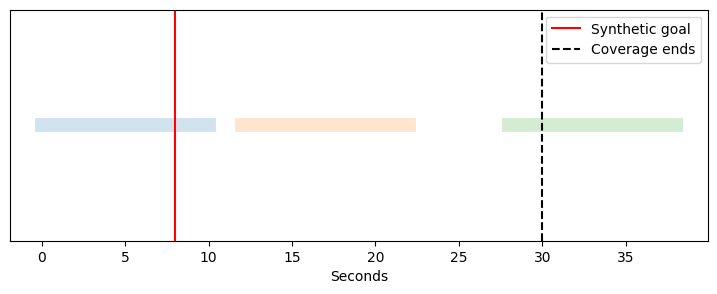

In [4]:
def goal_within_horizon(frames,goals,coverage_end,horizon=10):
    labels=pd.Series(np.nan,index=frames.index,dtype=float)
    for idx,r in frames.iterrows():
        end=coverage_end.get(r.period_id,-np.inf)
        if pd.isna(r.ball_owning_team_id) or r.seconds+horizon>end:continue
        eligible=goals.period.eq(r.period_id)&goals.team_id.eq(r.ball_owning_team_id)&goals.seconds.gt(r.seconds)&goals.seconds.le(r.seconds+horizon)
        labels.loc[idx]=float(eligible.any())
    return labels
toy_frames=pd.DataFrame({'period_id':[1,1,1],'seconds':[0,12,28],'ball_owning_team_id':[1,1,1]});toy_goals=pd.DataFrame({'period':[1],'seconds':[8.],'team_id':[1]})
labels=goal_within_horizon(toy_frames,toy_goals,{1:30.});display(pd.concat([toy_frames,labels.rename('target')],axis=1));assert labels.iloc[0]==1 and labels.iloc[1]==0 and pd.isna(labels.iloc[2])
fig,ax=plt.subplots(figsize=(9,3))
for t in toy_frames.seconds:ax.plot([t,t+10],[0,0],lw=10,alpha=.2)
ax.axvline(8,c='red',label='Synthetic goal');ax.axvline(30,c='black',ls='--',label='Coverage ends');ax.set(xlabel='Seconds',yticks=[]);ax.legend();plt.show()

## 5. Build node features from a real frame

Inspect the feature matrix before deciding graph edges.

In [5]:
nodes=snapshot.sort_values('player_id');ids=nodes.player_id.to_numpy();pos=nodes[['x','y']].to_numpy()
X=np.c_[pos/np.array([52.5,34]),nodes.team_id.eq(1802).astype(float)]
display(pd.DataFrame(X,index=ids,columns=['scaled_x','scaled_y','home_team']))

,scaled_x,scaled_y,home_team
11897,-0.452571,-0.264118,0.0
287934,0.102667,0.147941,1.0
50982,-0.489714,0.685882,0.0
50999,0.694286,0.025294,1.0
51002,-0.084000,0.048529,1.0
51043,-0.139429,0.952647,1.0
51050,0.164762,0.020294,1.0
51694,-0.322857,0.350882,0.0
560882,-0.141524,0.285882,1.0
560983,0.141714,-0.196176,1.0


## 6. Construct and normalize spatial adjacency

Inspect distances, thresholded edges and row normalization in calculation order.

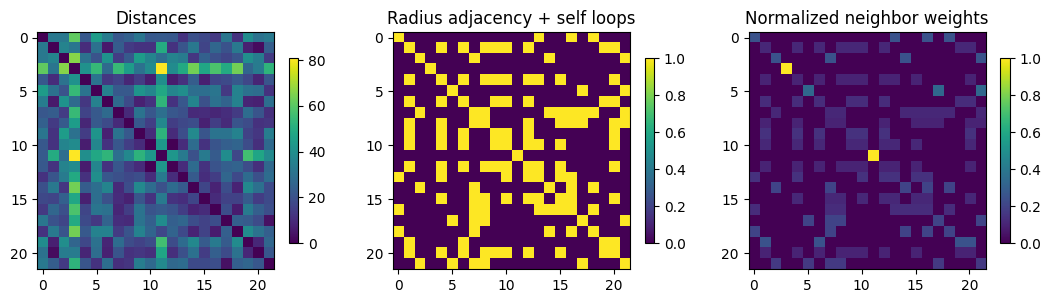

In [6]:
def adjacency_steps(position,radius):
    distance=np.sqrt(((position[:,None]-position[None])**2).sum(axis=-1))
    binary=(distance<=radius).astype(float)
    normalized=binary/binary.sum(axis=1,keepdims=True)
    return distance,binary,normalized
distance,binary,A=adjacency_steps(pos,15)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[distance,binary,A],['Distances','Radius adjacency + self loops','Normalized neighbor weights']):im=ax.imshow(data);ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.6)
plt.show();assert np.allclose(A.sum(axis=1),1)

## 7. Aggregate neighbors, transform and pool

Inspect message passing before attaching a scoring head. Parameters here are random, not learned soccer weights.

,node,own_x,neighbor_average_x,linear_0,hidden_0
0,11897,-0.452571,-0.399905,-0.010628,-0.010627
1,287934,0.102667,0.041989,-0.160209,-0.158852
2,50982,-0.489714,-0.385714,-0.054358,-0.054305
3,50999,0.694286,0.694286,-0.240885,-0.236332
4,51002,-0.084000,-0.028000,-0.114788,-0.114287
5,51043,-0.139429,-0.181333,-0.231112,-0.227084
6,51050,0.164762,0.064929,-0.151695,-0.150542
7,51694,-0.322857,-0.332656,-0.098002,-0.097689
8,560882,-0.141524,-0.145029,-0.142356,-0.141402
9,560983,0.141714,0.043293,-0.138079,-0.137208


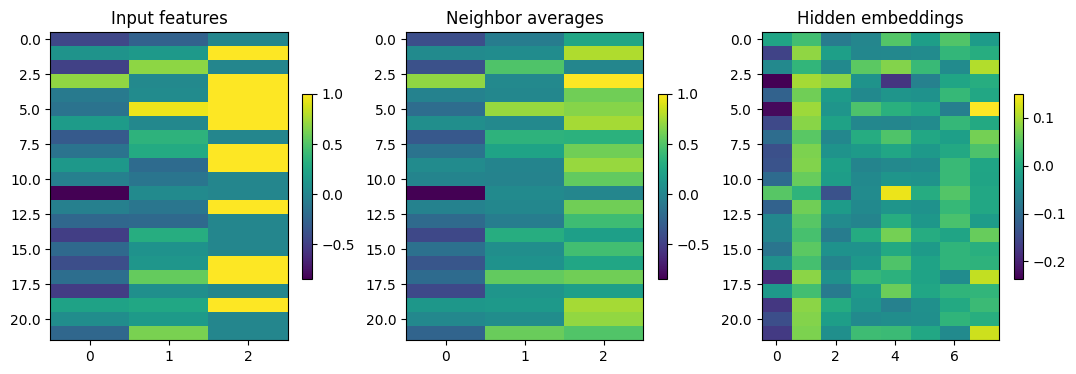

Mean-pooled graph embedding: [-0.1111  0.0614 -0.0382 -0.0273 -0.0017 -0.0246  0.0034  0.0301]


In [7]:
def message_steps(X,A,W):
    neighbor_average=A@X
    linear=neighbor_average@W
    hidden=np.tanh(linear)
    pooled=hidden.mean(axis=0)
    return neighbor_average,linear,hidden,pooled
rng=np.random.default_rng(4);W=rng.normal(0,.1,(X.shape[1],8));head=rng.normal(0,.1,8)
aggregate,linear,hidden,pooled=message_steps(X,A,W)
display(pd.DataFrame({'node':ids,'own_x':X[:,0],'neighbor_average_x':aggregate[:,0],'linear_0':linear[:,0],'hidden_0':hidden[:,0]}).head(10))
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[X,aggregate,hidden],['Input features','Neighbor averages','Hidden embeddings']):im=ax.imshow(data,aspect='auto');ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.6)
plt.show();print('Mean-pooled graph embedding:',pooled.round(4))

## 8. Inspect a forward score and backward gradients

Use one labeled synthetic graph to trace loss, pooling derivatives, the tanh derivative and shared-weight gradients before training.

,analytic,finite_difference
0,-0.069253,-0.069253


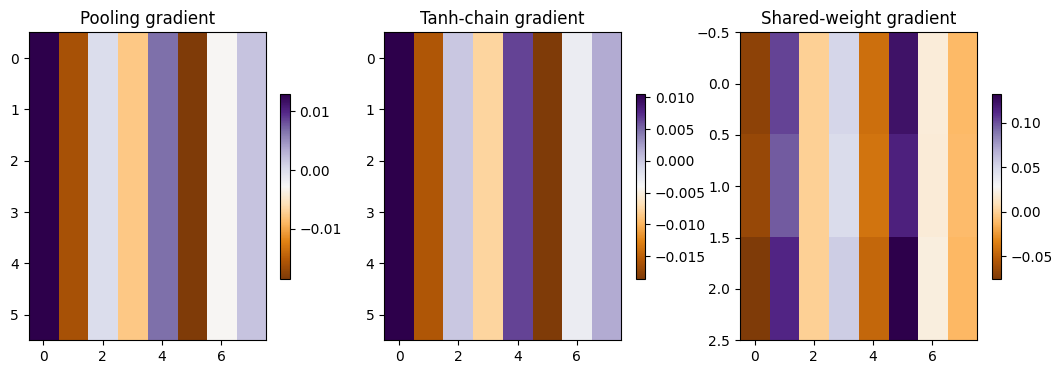

In [8]:
def graph_forward(X,A,W,head,bias):
    aggregated=A@X;hidden=np.tanh(aggregated@W);pooled=hidden.mean(axis=0);score=pooled@head+bias
    probability=1/(1+np.exp(-np.clip(score,-40,40)))
    return aggregated,hidden,pooled,score,probability
def graph_gradients(X,A,y,W,head,bias):
    aggregated,H,g,score,p=graph_forward(X,A,W,head,bias);error=p-y
    hidden_gradient=np.broadcast_to(error*head/len(X),H.shape);linear_gradient=hidden_gradient*(1-H**2)
    gradients={'W':aggregated.T@linear_gradient,'head':g*error,'bias':error}
    loss=np.logaddexp(0,score)-y*score
    return loss,gradients,hidden_gradient,linear_gradient
rng=np.random.default_rng(10);toy_X=rng.normal(-1,.3,(6,3));toy_A=np.ones((6,6))/6;toy_y=0
loss,gradient,hidden_gradient,linear_gradient=graph_gradients(toy_X,toy_A,toy_y,W,head,0.)
epsilon=1e-5;plus=W.copy();minus=W.copy();plus[0,0]+=epsilon;minus[0,0]-=epsilon
numeric=(graph_gradients(toy_X,toy_A,toy_y,plus,head,0.)[0]-graph_gradients(toy_X,toy_A,toy_y,minus,head,0.)[0])/(2*epsilon)
assert np.isclose(numeric,gradient['W'][0,0],rtol=1e-4,atol=1e-7)
display(pd.DataFrame({'analytic':[gradient['W'][0,0]],'finite_difference':[numeric]}))
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[hidden_gradient,linear_gradient,gradient['W']],['Pooling gradient','Tanh-chain gradient','Shared-weight gradient']):im=ax.imshow(data,aspect='auto',cmap='PuOr');ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.6)
plt.show()

## 9. Final output: train the inspected graph classifier

The training loop calls the gradient helper above. Synthetic feature-sign labels verify optimization only; real GraphEPV needs many independent labeled matches.

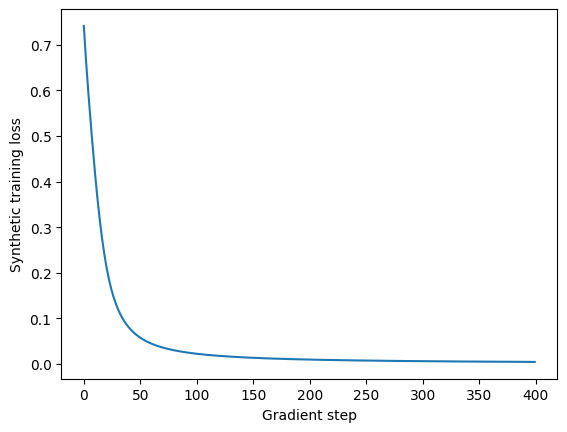

In [9]:
def train_gnn(graphs,labels,hidden=8,steps=400,lr=.1):
    rng=np.random.default_rng(11);W=rng.normal(0,.2,(graphs[0][0].shape[1],hidden));head=rng.normal(0,.2,hidden);bias=0.;losses=[]
    for _ in range(steps):
        dW=np.zeros_like(W);dh=np.zeros_like(head);db=0.;total_loss=0.
        for (X,A),y in zip(graphs,labels):
            loss,grad,_,_=graph_gradients(X,A,y,W,head,bias);dW+=grad['W'];dh+=grad['head'];db+=grad['bias'];total_loss+=loss
        n=len(graphs);W-=lr*dW/n;head-=lr*dh/n;bias-=lr*db/n;losses.append(total_loss/n)
    return W,head,bias,losses
rng=np.random.default_rng(10);graphs=[];targets=[]
for i in range(40):
    y=i%2;graphs.append((rng.normal(2*y-1,.3,(6,3)),np.ones((6,6))/6));targets.append(y)
trained_W,trained_head,trained_bias,losses=train_gnn(graphs,targets);assert losses[-1]<losses[0]
plt.plot(losses);plt.xlabel('Gradient step');plt.ylabel('Synthetic training loss');plt.show()
permutation=np.random.default_rng(3).permutation(len(X));p=graph_forward(X,A,W,head,0.)[-1];permuted=graph_forward(X[permutation],A[np.ix_(permutation,permutation)],W,head,0.)[-1];assert np.isclose(p,permuted)

## Interpretation and limitations

This is a minimal independent graph classifier, not exact UnravelSports architecture or pretrained GraphEPV inference. The home-team indicator illustrates tensors; real training should orient/encode the possession team consistently. Group splits by matches/possessions, inspect calibration and censor unknown horizons. [Bekkers GraphEPV](https://rawcdn.githack.com/UnravelSports/keynotes/main/html/20250607-PyData-London.html).